# Week 2: Build the Virtual Town

Goal: Build a town of 100 people who meet each other randomly, and watch an outbreak move through it for 60 days.

Find your name below and follow the instructions for your role. You'll find guidance here, but you'll write your own solutions.

## From equations to people

In Week 1, our SIR and SEIR models tracked four big groups, using rates to calculate how many people moved between groups each day, and the results were smooth curves.

This week we model the same idea person by person, following our project proposal's design: a small town of simulated people who meet each other randomly, and each day a meeting with a sick person can pass the disease on. When an infectious person meets a susceptible person, the infection might pass or it might not, so we draw a random number to decide, which means every run can tell a slightly different story. This style of model is called an agent-based model, because each "agent" is one simulated person.

We will also watch the disease spread through the town: each dot in the notebook is one person, its color shows their health state, and a line appears whenever two people meet.

## What each person can be

We use the same four letters as Week 1, though now they describe one person at a time.

Susceptible (S): The person has not been infected but could catch the disease.

Exposed (E): The person is infected but not yet infectious.

Infectious (I): The person can currently spread the disease in meetings.

Recovered (R): The person is no longer infectious and cannot be infected again in our simple model.

A person moves in one direction only, so S becomes E when infection passes in a meeting, E becomes I after 5 days, and I becomes R after 10 days.

## Starting scenario

The town has 100 people, like Week 1, and on Day 0 one person is infectious while everyone else is susceptible.

Population equation for every day:

$S+E+I+R=N$

Unlike Week 1, every value is a whole number of people, and the model is still a teaching example rather than a forecast of a real outbreak.

## Week 2 simulation inputs

| Input | Value | Tag |
| :--- | ---: | :--- |
| Total people (N) | 100 | ASSUMPTION |
| Starting infectious | 1 | ASSUMPTION |
| Meetings per infectious person per day | 3 | ASSUMPTION |
| Infection chance per meeting | 0.15 | ASSUMPTION |
| Days before infectious (exposed) | 5 | ASSUMPTION |
| Days infectious before recovering | 10 | ASSUMPTION |
| Simulation duration | 60 days | ASSUMPTION |
| Random seed | 42 | Teaching tool |

## Sources and assumptions

Every input above is an ASSUMPTION chosen for teaching, following our project rule that tags every number as SOURCED (a source says it), DERIVED (calculated from sourced numbers), or ASSUMPTION (our choice, said plainly). When we compare diseases in Week 3, these teaching values are replaced with sourced numbers from the project sources in [research/README.md](../research/README.md).

Three honest notes about these inputs:

1. **The infection chance is not Week 1's beta.** In Week 1, beta was a daily rate applied to the whole population, whereas here 0.15 is the chance that infection passes in one meeting between an infectious person and a susceptible person.
2. **Fixed day counts are a simplification.** Real timing varies from person to person, so we use fixed values of 5 exposed days and 10 infectious days to keep the code readable this week, and these also match the averages from Week 1's sigma = 0.20 and gamma = 0.10, because 1 divided by a daily rate gives an average number of days.
3. **The random seed makes results checkable.** Setting `random.seed(42)` before the simulation means everyone who runs the same code gets the same random numbers and the same result, whilst changing the seed gives a different outbreak, which is also correct.

We run 60 days this week instead of 30, because in Week 1 thirty days was not always enough to see the rise, the peak, and the decline: our SEIR run had not peaked by Day 30.

## Team responsibilities

Jayden: Explain how the town model works.

Linh: Build the town of 100 people and save the Day 0 counts.

Ayush: Run the meetings and the spread for 60 days. Save the five lists and a daily snapshot of the town.

Ei Kay: Show the town as it happens, and turn the lists into a line graph.

Alex: Check the town and report which tests pass.

Project leader: Review each contribution and combine the results.

## Jayden: Explain the Town Model

### Your steps

1. Read the "From equations to people" and "Sources and assumptions" sections and the Week 2 simulation inputs table.
2. Explain in your own words what one person, one meeting, and the infection chance mean in this model.
3. Explain why we use a random seed.
4. Explain one way this model is different from the Week 1 equations.
5. Point out which inputs are assumptions.
6. Share your explanation with Linh and Ayush before they write their code, because their work follows directly from how you describe the model.

Write your explanation in the Markdown cell directly below. No code is needed.

For the separate written assignment questions and instructions on submitting your personal Week 2 Markdown file, scroll to the bottom of the notebook.

### My Town Model Explanation

What one person is in the model:
In this model, one person is represented by one dot in the notebook. The color of the dot shows their health status: Susceptible (S), Exposed (E), Infectious (I), or Recovered(R).

What a meeting means:
A meeting will appear as a line whenever two people meet. The meetings are at random, and each infectious individual has 3 meetings per day with a randomly chosen person. Meetings between an infectious person and a susceptible person have a chance to pass the infection on.

What the infection chance of 0.15 means:
There is a 15% chance that an infectious individual passes the infection to a susceptible individual in a single meeting. This contrasts with Week 1’s beta, which was a daily rate applied to the entire population, whereas 0.15 applies for each meeting between two people.

Why we use a random seed:
We use a random seed in this model because it ensures that everyone who runs the same code gets the same random numbers and result. In other words, it ensures that the results are reproducible. The random seed 42 is used as a teaching tool, and changing the seed gives a different but equally valid outbreak.

How this model is different from the Week 1 equations:
The previous Week 1 models track four big groups and use daily rates to calculate how many people move between groups. In contrast, this Week 2 model follows each of the 100 people in the town individually. When a meeting with an infectious person and a susceptible person happens, a random number is drawn to decide whether the infection will pass on. This form of model is called an agent-based model, meaning every run can have a slightly different story. Furthermore, individuals move through the different states using fixed day counts for simplification (5 exposed days and 10 infectious days). These also match the rates from Week 1: sigma = 0.20 and gamma = 0.10, by dividing 1 by the daily rate to give the average number of days. 

Which inputs are assumptions:
All of the inputs are tagged ASSUMPTIONS chosen for teaching: total people (N= 100), starting infectious (1), meetings per infectious person per day(3), infection chance per meeting (0.15), days before infectious (5), days infectious before recovering (10), and simulation duration (60 days). Later on in Week 3, these assumptions will be replaced with sourced numbers from the project sources. 

## Linh: Build the Town

Your job is to create the 100 people and record the Day 0 counts. You will write Python in the empty code cell below. If dictionaries or functions are new, read [Python for the town](../learning/Week_02/01_Python_for_the_Town.md) sections 1 and 2 first.

### Step 1: Understand what one person looks like

Each person is a Python dictionary:

```python
person = {"id": 0, "state": "S", "days_exposed": 0, "days_infectious": 0}
```

- `id` is the person's number, from 0 to 99.
- `state` is one of the four letters: "S", "E", "I", or "R".
- `days_exposed` counts how many days the person has been in the exposed group.
- `days_infectious` counts how many days the person has been infectious.

### Step 2: Build the town

1. Create an empty list called `town`.
2. Use a `for` loop to add 100 people to it, with ids 0 to 99. Every person starts with state "S" and both counters at 0.
3. After the loop, set the person with id 0 to state "I". This is the one infectious person on Day 0.

### Step 3: Count the states

Write a helper function called `count_states(town)`:

1. Start a dictionary with the four letters, each counting from 0.
2. Loop through every person and add 1 to the count for their state.
3. Return the dictionary.

This is our first helper function in the project, and Teammates 3 and 5 will reuse it instead of copying the same loop.

### Step 4: Save the Day 0 counts

Create five lists: `town_days`, `town_S`, `town_E`, `town_I`, and `town_R`. Save the day number 0 and the Day 0 counts into them, the same way Week 1 saved Day 0 first.

### Step 5: Check your result

Day 0 should be 99 susceptible, 0 exposed, 1 infectious, and 0 recovered. The five lists should each hold exactly one value.

Write your code in the cell below.

Scroll to the bottom of this notebook for your written questions and step by step instructions to submit your answers in your personal Markdown file.

In [1]:
# Build the town: write your code here
# 1. Create an empty list called town
town = []

# 2. Use a loop to add 100 people (ids 0 to 99), each starting with state "S" and both counters at 0
import random
for num in range(100):
    person =  {"id": num, "state": "S", "days_exposed": 0, "days_infectious": 0}
    town.append(person)

# 3. Set the person with id 0 to state "I"
town[0]["state"] = "I"

# 4. Write the count_states(town) helper function
def count_states(town):
    counts = {"S":0, "E":0, "I":0, "R":0}
    for person in town:
        counts[person['state']] +=1
    return counts

# 5. Create the five lists (town_days, town_S, town_E, town_I, town_R) and save the Day 0 counts
town_days = []
town_S = []
town_E = []
town_I = []
town_R = []

day0_counts = count_states(town)

town_days.append(0)
town_S.append(day0_counts["S"])
town_E.append(day0_counts["E"])
town_I.append(day0_counts["I"])
town_R.append(day0_counts["R"])

# 6. Print the Day 0 counts to check them
print(day0_counts)
print(town_days)
print(town_S)
print(town_E)
print(town_I)
print(town_R)

{'S': 99, 'E': 0, 'I': 1, 'R': 0}
[0]
[99]
[0]
[1]
[0]


### Example output: Day 0 counts

Your program should save these five lists after Day 0:

```text
town_days = [0]

town_S = [99]

town_E = [0]

town_I = [1]

town_R = [0]
```

Ayush will add one entry to each list for every day of the outbreak.

## Ayush: Run the Outbreak

Your job is to simulate 60 days of meetings and spread, and record the counts each day. You will write Python in the empty code cell below. If the random module, tuples, or snapshots are new, read [Python for the town](../learning/Week_02/01_Python_for_the_Town.md) sections 3 to 6 first.

### Step 1: Get the town

Run Linh's code cell first so `town`, `count_states`, and the five lists exist.

### Step 2: See how Day 1 works

On each day, two things happen in order: meetings, then timers.

**Meetings.** Every infectious person meets 3 randomly chosen people that day. For each meeting, draw a random number between 0 and 1. Infection passes only if the person met is susceptible **and** the random number is smaller than 0.15.

Example: on Day 1, person 0 is the only infectious person. Say their 3 random meetings are with people 12, 47, and 88, and the three random numbers drawn are 0.42, 0.09, and 0.77. Person 12 stays susceptible (0.42 is not below 0.15). Person 47 becomes exposed (0.09 is below 0.15). Person 88 stays susceptible (0.77 is not below 0.15).

**One important rule:** collect all of the day's newly exposed people in a list first, and change their states to "E" only after every meeting is finished. This is the same idea as Week 1, where we calculated the changes using the current S, E, and I before changing any group. If the same susceptible person is chosen twice in one day, count them only once.

**Timers.** After meetings, move time forward for everyone who is exposed or infectious:

- Each exposed person gains 1 exposed day. When `days_exposed` reaches 5, the person becomes infectious and `days_infectious` starts at 0.
- Each infectious person gains 1 infectious day. When `days_infectious` reaches 10, the person becomes recovered.

### Step 3: Write your Python

1. Set `random.seed(42)` once, before the day loop, so the whole team gets the same result.
2. Use a `for` loop to repeat the Day 1 steps for days 1 to 60.
3. For meetings, loop through the town. For each infectious person, use `random.choice(town)` 3 times to choose who they meet, and `random.random()` once per meeting for the infection draw. Record each meeting as a pair of ids, `(person["id"], other["id"])`.
4. Remember the order: collect newly exposed ids, change their states after all meetings, then advance the timers.
5. After the timers, use `count_states(town)` and `append()` to save the day number and the four counts to the five lists.
6. Save what the town display needs. Before the day loop, create `town_snapshots` and `town_meetings`, each with a Day 0 entry (the starting states, and an empty meeting list). Each day, append that day's meeting pairs to `town_meetings`, and after the timers append `[person["state"] for person in town]` to `town_snapshots`. Ei Kay uses these to show the town.

### Step 4: Check your result

You should have 61 days saved, starting with Day 0 and ending with Day 60. On every day, S + E + I + R should equal 100, and every count should be a whole number.

With seed 42, the infectious group peaks at 43 people on Day 31, and by Day 60 almost everyone has recovered. Your result should match this when you use the same seed.

Write your code in the cell below. The Day 1 example above is an example, not the complete Python solution.

Scroll to the bottom of this notebook for your written questions and step by step instructions to submit your answers in your personal Markdown file.

In [2]:
# Run the outbreak: write your code here
import random

# 1. Set random.seed(42) before the day loop
random.seed(42)

# 2. Create town_snapshots and town_meetings with their Day 0 entries
town_snapshots = [[person["state"] for person in town]]
town_meetings = [[]]

# 3. Loop over days 1 to 60
for day in range(1, 61):
    daily_meetings = []
    newly_exposed_ids = []

# 4. Meetings: each infectious person meets 3 random people; collect newly exposed ids
    for person in town:
        if person["state"] == "I":
            for _ in range(3):
                other = random.choice(town)
                daily_meetings.append((person["id"], other["id"]))

#    (infection passes only when the person met is "S" and the random draw is below 0.15)
                if other["state"] == "S":
                    if random.random() < 0.15:
                        if other["id"] not in newly_exposed_ids:
                            newly_exposed_ids.append(other["id"])
#    and record each meeting as a pair of ids

# 5. After all meetings, set the newly exposed people to "E" with days_exposed = 0
    for pid in newly_exposed_ids:
        town[pid]["state"] = "E"
        town[pid]["days_exposed"] = 0
        town[pid]["days_infectious"] = 0

# 6. Advance the timers: exposed people become infectious after 5 days, infectious people recover after 10 days
    for person in town:
        if person["state"] == "E":
            person["days_exposed"] += 1
            if person["days_exposed"] >= 5:
                person["state"] = "I"
                person["days_exposed"] = 0
                person["days_infectious"] = 0
        elif person["state"] == "I":
            person["days_infectious"] += 1
            if person["days_infectious"] >= 10:
                person["state"] = "R"
                person["days_exposed"] = 0
                person["days_infectious"] = 0

# 7. Count the states and save the day number and counts to the five lists
    counts = count_states(town)
    town_days.append(day)
    town_S.append(counts["S"])
    town_E.append(counts["E"])
    town_I.append(counts["I"])
    town_R.append(counts["R"])

# 8. Save the display data: append today's meeting pairs to town_meetings
#    and the day's states to town_snapshots
    town_meetings.append(daily_meetings)
    town_snapshots.append([p["state"] for p in town])




## Ei Kay: Show the Town and Make the Graph

Your job has two parts: make the outbreak something the team can watch, and turn the five lists from Ayush into one line graph. Read [Drawing the town](../learning/Week_02/02_Drawing_the_Town.md) before you start; it explains every drawing tool below.

### Step 1: Get the results

Run the town and outbreak code cells first so the five lists, `town_snapshots`, and `town_meetings` exist.

### Step 2: Show the town

We draw the town as a grid of 100 dots, one dot per person. The color of a dot is the person's state that day. Thin gray lines show that day's meetings: each line connects the two people who met.

One honest rule about this picture: **where a dot sits on the grid means nothing.** People do not live at their grid spot, and dots do not move. In our model any two people can meet, and the gray lines show who actually met. Only the colors and the lines carry information.

The code cell below gives you the grid positions and the state colors. You write a function `draw_town(ax, states, meetings, day)` that draws one day:

1. Clear the axes and set the title to "Virtual Town - Day " plus the day number.
2. For each meeting pair `(a, b)` in `meetings`, draw a thin gray line between `POSITIONS[a]` and `POSITIONS[b]`.
3. For each of the four states, draw the dots of the people in that state using `COLORS[state]`.
4. Hide the axis numbers, and add a legend naming the four states.

Then the given animation code calls your function once per day, so the team can watch the colors and meetings change over the 60 days.

With seed 42, you should see one red dot on Day 0, red and orange spreading across the grid with many meeting lines around Day 31, and almost every dot green by Day 60.

### Step 3: Make the graph

1. Use `town_days` for the horizontal axis.
2. Draw four lines using `town_S`, `town_E`, `town_I`, and `town_R`.
3. Give the graph the title "Virtual Town Outbreak". Label the axes "Day" and "Number of people".
4. Keep both axes in whole numbers (no decimal tick labels). The counts are already whole people.
5. Add a legend, show the graph, and save the image in `results/`.

### Step 4: Describe what you see

Write two or three short sentences: When does the infectious group grow, when does it peak, and when does it shrink? Then compare with Week 1: the Week 1 graphs were smooth curves, while this graph is jagged. Why? (Hint: think about randomness.)

### Step 5: Compare the town with the simple model

Our proposal's checking rule is that the town and the simple model should tell the same overall story. Put your town graph next to the Week 1 SEIR graph and write one sentence: do both show one rise, one peak, and one decline? If the two do not match at all, tell the project leader, because that is how we find bugs.

Your finished work is the town display, one graph, and your sentences, not tables. Write your Python in the code cell below.

Scroll to the bottom of this notebook for your written questions and step by step instructions to submit your answers in your personal Markdown file.

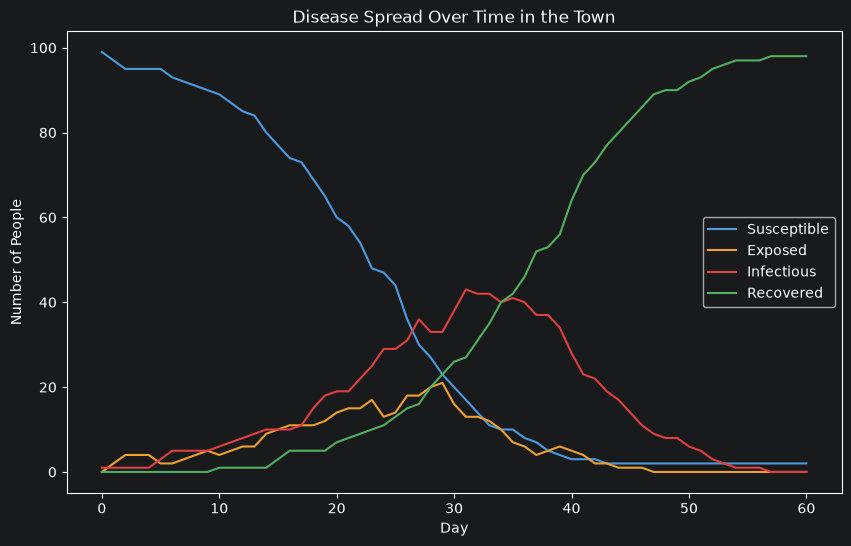

In [3]:
# Show the town: grid positions and colors are given; you write draw_town
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Given: a fixed grid spot for each person, ids 0 to 99. The spot means nothing; only meetings matter.
POSITIONS = [(i % 10, i // 10) for i in range(100)]

# Given: one color per state
COLORS = {"S": "#4C9BE0", "E": "#F0A030", "I": "#E04040", "R": "#50B060"}

# Write draw_town(ax, states, meetings, day):
def draw_town(ax, states, meetings, day):
    # 1. clear the axes and set the title "Virtual Town - Day <day>"
    ax.clear()
    ax.set_title(f"Virtual Town - Day {day}")
    # 2. for each meeting pair (a, b), draw a thin gray line between POSITIONS[a] and POSITIONS[b]
    for a, b in meetings:
        ax.plot([POSITIONS[a][0], POSITIONS[b][0]], [POSITIONS[a][1], POSITIONS[b][1]], color="gray", linewidth=0.5)
    for state, color in COLORS.items():
        # 3. for each state, draw the dots of the people in that state using COLORS[state]
        xs = [POSITIONS[i][0] for i, s in enumerate(states) if s == state]
        ys = [POSITIONS[i][1] for i, s in enumerate(states) if s == state]

        ax.scatter(xs, ys, c=color, label=state)

# hide the axis ticks and add a legend for the four states
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend()

# Then run the animation (given):
fig, ax = plt.subplots(figsize=(6, 6))
def update(frame):
    draw_town(ax, town_snapshots[frame], town_meetings[frame], frame)
anim = FuncAnimation(fig, update, frames=len(town_snapshots), interval=300)
plt.close(fig)
display(HTML(anim.to_jshtml()))


# Line graph: write your plotting code below (town_days, town_S, town_E, town_I, town_R)
plt.figure(figsize=(10, 6))
plt.plot(town_days, town_S, label="Susceptible", color=COLORS["S"])
plt.plot(town_days, town_E, label="Exposed", color=COLORS["E"])
plt.plot(town_days, town_I, label="Infectious", color=COLORS["I"])
plt.plot(town_days, town_R, label="Recovered", color=COLORS["R"])
plt.xlabel("Day")
plt.ylabel("Number of People")
plt.title("Disease Spread Over Time in the Town")
plt.legend()
plt.show()


## Alex: Test the Town Simulation

Your job is to check the town and the lists created by Linh and Ayush. If test patterns are new, read [Python for the town](../learning/Week_02/01_Python_for_the_Town.md) section 8 first.

### Step 1: Get the results

Run the town and outbreak code cells first.

### Step 2: Check the lists

1. Check that each of the five lists contains 61 values. Day 0 through Day 60 means 61 entries.
2. Check Day 0 by hand: 99 susceptible, 0 exposed, 1 infectious, 0 recovered.
3. Use a loop to check that the four counts add up to 100 on every day. The counts are whole numbers now, so no rounding allowance is needed.
4. Use a loop to check that no count is ever negative.
5. Use a loop to check that every person's state is always one of "S", "E", "I", or "R".

### Step 3: Check the randomness

1. Run the outbreak cell again with the same seed, 42. The final counts should be identical to the first run.
2. Change the seed to a different number, such as 7, and run again. The counts should be different, but checks 1 to 5 above should still pass, even if that run's outbreak dies out early by chance.
3. Set the seed back to 42 when you are done, so the rest of the team sees the same result.

### Step 4: Report the results

Print PASS when a test succeeds and FAIL when it does not. If something fails, say which check and which day failed.

Use the existing town and lists. Do not rewrite the simulation.

Write your testing Python in the code cell below.

Scroll to the bottom of this notebook for your written questions and step by step instructions to submit your answers in your personal Markdown file.

In [4]:
# Testing: write your checks here
if (
len(town_days) == 61
and len(town_S) == 61
and len(town_E) == 61
and len(town_I) == 61
and len(town_R) == 61
):
    print("61 daily records: PASS")

if (
    town_S[0] == 99
and town_E[0] == 0
and town_I[0] == 1
and town_R[0] == 0
):
    print ("Day 0 counts are 99, 0, 1, 0: PASS")

for day in range (61):
 total = town_S[day] + town_E[day] + town_I[day] + town_R[day]
if total == 100:
   print("Population total remains 100: PASS")

for day in range (61):
    if (
        town_S[day] >= 0 
        and town_E[day] >= 0 
        and town_I[day] >= 0 
        and town_R[day] >= 0 
    ):
        print("No negative counts: PASS")

for day in range(len(town_snapshots)):
   states_ok = True

   for person_id in range (len(town_snapshots[day])):
      state = town_snapshots[day][person_id]

      if state not in ["S","E","I","R"]:
        print ("Valid state on day")

first_result = [
    town_S[-1], town_E[-1], town_I[-1], town_R[-1]
]

second_result = [
    town_S[-1], town_E[-1], town_I[-1], town_R[-1]
]

if first_result == second_result:
    print("Same seed gives the same result: PASS")

checks_passed = True

# Check 1: List lengths
if (
    len(town_days) != 61
    or len(town_S) != 61
    or len(town_E) != 61
    or len(town_I) != 61
    or len(town_R) != 61
):
    print("List lengths: FAIL")
    checks_passed = False

else:
    # Check 2: Day 0
    if (
        town_S[0] != 99
        or town_E[0] != 0
        or town_I[0] != 1
        or town_R[0] != 0
    ):
        print("Day 0 counts: FAIL")
        checks_passed = False

    for day in range(61):
        # Check 3: Population total
        total = town_S[day] + town_E[day] + town_I[day] + town_R[day]

        if total != 100:
            print("Population total on day", day, ": FAIL")
            checks_passed = False

        # Check 4: Negative counts
        if (
            town_S[day] < 0
            or town_E[day] < 0
            or town_I[day] < 0
            or town_R[day] < 0
        ):
            print("Negative count on day", day, ": FAIL")
            checks_passed = False

# Check 5: Valid states in all daily snapshots
if len(town_snapshots) != 61:
    print("Daily snapshots: FAIL")
    checks_passed = False

for day in range(len(town_snapshots)):
    for person_id in range(len(town_snapshots[day])):
        state = town_snapshots[day][person_id]

        if state not in ["S", "E", "I", "R"]:
            print("Invalid state on day", day,
                  "for person", person_id, ": FAIL")
            checks_passed = False

# Report the overall result
if checks_passed:
    print("Different seed still passes all checks: PASS")


61 daily records: PASS
Day 0 counts are 99, 0, 1, 0: PASS
Population total remains 100: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No negative counts: PASS
No nega

## Week 2 written questions

Jayden (explanation): How does the town model spread disease? Which of this week's inputs are assumptions?

Linh (town): How did you build the town? What does each person's dictionary store?

Ayush (outbreak): How do meetings and the infection chance work in your code? Why do you collect the newly exposed people before changing any states?

Ei Kay (town display and graph): In your town display, what do the dot colors and the gray lines each show? When does the infectious group peak, and why is this curve jagged when the Week 1 curves were smooth? Does your town graph tell the same overall story as the Week 1 SEIR graph?

Alex (testing): What did you test? Which tests passed or failed? What happened when you changed the seed?

Write your answers in your own Week 2 Markdown file. Follow the [Submission Guide](../SUBMISSION_GUIDE.md) for where to find your file and how to submit it.